## Ćwiczenie 6 – Rozszerzenie 3: Interaktywne strojenie parametrów detekcji krawędzi (`ipywidgets`)

### 1. Podbudowa Teoretyczna

#### Problem wrażliwości na hiperparametry w przetwarzaniu obrazów medycznych
Algorytmy wyostrzania i detekcji krawędzi są niezwykle wrażliwe na dobrane parametry, takie jak:
* **$\sigma$ (Rozmiar filtra Gaussa):** Decyduje o skali analizowanych struktur (małe $\sigma$ wykrywa drobne detale i szum, duże $\sigma$ zachowuje tylko główne zarysy anatomiczne).
* **Progi binaryzacji ($T$):** Wpływają na kompromis między fałszywie dodatnimi (*False Positives*) a fałszywie ujemnymi (*False Negatives*) krawędziami.

W środowisku klinicznym inżynier medyczny często buduje interfejsy z suwakami, aby radiolog mógł elastycznie dopasować parametry do konkretnej serii tomograficznej. Użycie pakietu `ipywidgets` pozwala na symulację tego procesu wewnątrz Jupyter Notebooka.

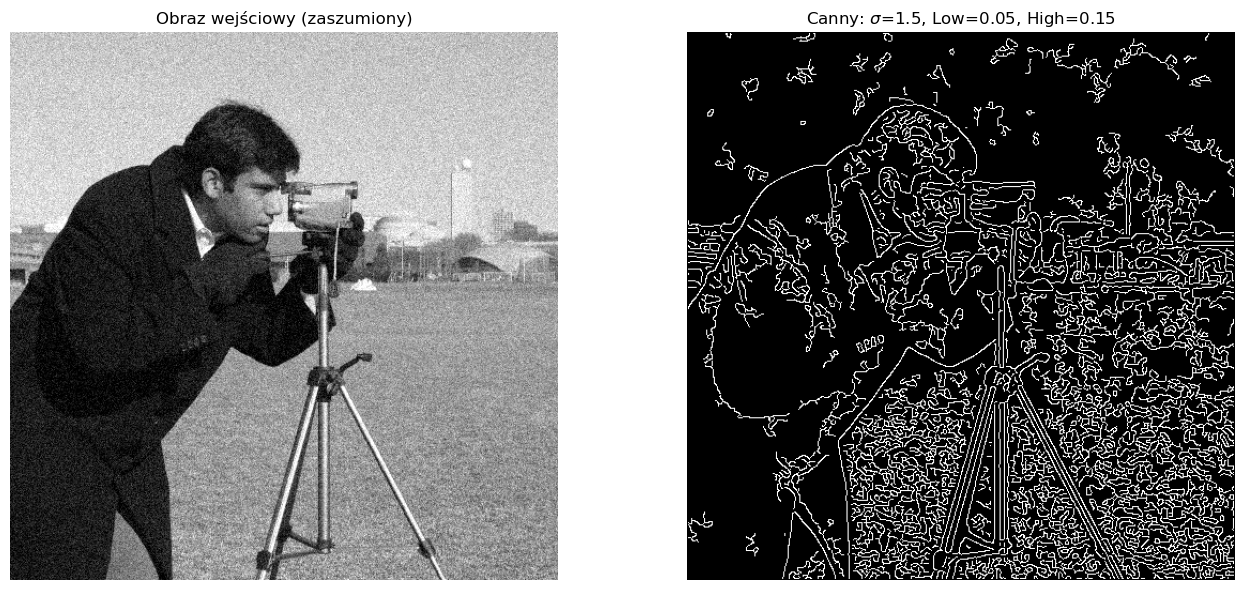

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, feature, filters, util
import ipywidgets as widgets
from ipywidgets import interactive

# Przygotowanie obrazu medycznego/referencyjnego z szumem
image = data.camera() / 255.0
noisy_image = util.random_noise(image, mode='gaussian', var=0.005)

# Definicja funkcji interaktywnej dla Canny'ego
def process_canny(sigma, low_th, high_th):
    edges = feature.canny(
        noisy_image, 
        sigma=sigma, 
        low_threshold=low_th, 
        high_threshold=high_th
    )
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    ax1.imshow(noisy_image, cmap='gray')
    ax1.set_title('Obraz wejściowy (zaszumiony)')
    ax1.axis('off')
    
    ax2.imshow(edges, cmap='gray')
    ax2.set_title(rf'Canny: $\sigma$={sigma:.1f}, Low={low_th:.2f}, High={high_th:.2f}')
    ax2.axis('off')
    
    plt.tight_layout()
    plt.show()

'''
# Tworzenie interaktywnych suwaków
widget_node = interactive(
    process_canny,
    sigma=widgets.FloatSlider(min=0.5, max=4.0, step=0.1, value=1.5, description='Sigma (Gauss)'),
    low_th=widgets.FloatSlider(min=0.01, max=0.2, step=0.01, value=0.05, description='Low Thresh'),
    high_th=widgets.FloatSlider(min=0.05, max=0.4, step=0.01, value=0.15, description='High Thresh')
)

display(widget_node)
'''

process_canny(sigma=1.5, low_th=0.05, high_th=0.15)

### Instrukcja dla studenta:
1. Uruchom powyższą komórkę.
2. Ustaw `high_th` na bardzo niską wartość i zaobserwuj wzrost fałszywych krawędzi wynikających z szumu.
3. Zwiększaj `sigma` i zobacz, jak znikają drobne krawędzie, a pozostają jedynie grube zarysy głównych obiektów.